# Phân tích dữ liệu lặn và bão hòa Hemoglobin ở chim cánh cụt

Notebook này phân tích hai file là kết quả của `merge_data_new.ipynb`:

| File | Nội dung | Kích thước |
|---|---|---|
| `penguin_dives.csv` | Danh mục **160 lần lặn** (1 dòng / lần lặn) | 160 × 14 |
| `penguin_merged.csv` | Chuỗi thời gian PO2 / Hb / độ sâu (1 dòng / mẫu đo) | 29.511 × 15 |

**Mục lục**
1. Nạp dữ liệu và kiểm tra chất lượng
2. Danh mục lần lặn: độ sâu, thời lượng, nhóm
3. Chuỗi thời gian Hb/PO2: tổng quan
4. Hb theo pha (ngoài lặn / trong lặn) và theo độ sâu
5. Diễn biến Hb trong một lần lặn
6. Tóm tắt từng lần lặn (nối hai bảng) và kiểm định thống kê
7. Kết luận

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

from pathlib import Path
DIR = "../data"                  # notebook nằm trong notebooks/, CSV nằm trong data/
OUT = Path("../analysis")        # ảnh xuất ra đây (tự tạo nếu chưa có)
OUT.mkdir(parents=True, exist_ok=True)
_fig_n = 0

def save_show(name):
    # Lưu hình hiện tại vào analysis/ rồi hiển thị
    global _fig_n
    _fig_n += 1
    plt.savefig(OUT / f"{_fig_n:02d}_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
dives = pd.read_csv(f"{DIR}/penguin_dives.csv")
ts    = pd.read_csv(f"{DIR}/penguin_merged.csv")
print("dives:", dives.shape, "| ts:", ts.shape)

dives: (160, 14) | ts: (29511, 15)


## 1. Nạp dữ liệu và kiểm tra chất lượng

In [2]:
print("=== penguin_dives.csv ===")
display(dives.head())
display(dives.dtypes.to_frame("dtype").T)

print("=== penguin_merged.csv ===")
display(ts.head())
display(ts.dtypes.to_frame("dtype").T)

=== penguin_dives.csv ===


,group,bird,dive_id,start,end,max_depth,dur_min,date,max_depth_1hz,n_samples,max_depth_obs,coverage_pct,is_valid_dive,max_depth_clean
0,Type A venous,EP04,EP04 1,32614,32837,16.5,3.716667,2003-11-14,16.5,15,16.0,94.170404,True,16.5
1,Type B venous,EP05,EP05 1,74478,74665,13.5,3.116667,2003-11-17,13.5,38,13.5,98.930481,True,13.5
2,Arterial,EP02,EP02 2,32526,32711,24.0,3.083333,2003-11-23,27.5,13,25.5,97.297297,True,24.0
3,Type A venous,EP04,EP04 2,32960,33141,20.5,3.016667,2003-11-14,20.5,12,20.0,91.160221,True,20.5
4,Type B venous,EP05,EP05 5,76580,76916,56.9,5.600000,2003-11-17,61.0,67,61.0,98.214286,True,56.9


,group,bird,dive_id,start,end,max_depth,dur_min,date,max_depth_1hz,n_samples,max_depth_obs,coverage_pct,is_valid_dive,max_depth_clean
dtype,str,str,str,int64,int64,float64,float64,str,float64,int64,float64,float64,bool,float64


=== penguin_merged.csv ===


,bird,site,group,dive_id,t,tod,date,t_in_dive_s,dive_dur_min,PO2,Hb_pct,Hb,depth_m,excluded_dive,unlisted_dive
0,EP01,arterial,NaN,NaN,1.227686e+09,28380.0,2008-11-26,NaN,NaN,63.0,91.306235,0.913062,0.0,False,False
1,EP01,arterial,NaN,NaN,1.227686e+09,28385.0,2008-11-26,NaN,NaN,62.0,90.927360,0.909274,0.0,False,False
2,EP01,arterial,NaN,NaN,1.227686e+09,28390.0,2008-11-26,NaN,NaN,62.0,90.927360,0.909274,0.0,False,False
3,EP01,arterial,NaN,NaN,1.227686e+09,28395.0,2008-11-26,NaN,NaN,63.0,91.306235,0.913062,0.0,False,False
4,EP01,arterial,NaN,NaN,1.227686e+09,28400.0,2008-11-26,NaN,NaN,63.0,91.306235,0.913062,0.0,False,False


,bird,site,group,dive_id,t,tod,date,t_in_dive_s,dive_dur_min,PO2,Hb_pct,Hb,depth_m,excluded_dive,unlisted_dive
dtype,str,str,str,str,float64,float64,str,float64,float64,float64,float64,float64,float64,bool,bool


In [3]:
def quality(df, name):
    q = pd.DataFrame({
        "thiếu": df.isna().sum(),
        "% thiếu": (df.isna().mean() * 100).round(2),
        "số giá trị duy nhất": df.nunique(),
    })
    print(f"--- {name}: {len(df):,} dòng, trùng lặp hoàn toàn = {df.duplicated().sum()} ---")
    display(q[q["thiếu"] > 0])

quality(dives, "dives")
quality(ts, "ts")

--- dives: 160 dòng, trùng lặp hoàn toàn = 0 ---


,thiếu,% thiếu,số giá trị duy nhất
date,17,10.62,14
max_depth_1hz,3,1.88,93
max_depth_obs,3,1.88,86
coverage_pct,3,1.88,137


--- ts: 29,511 dòng, trùng lặp hoàn toàn = 0 ---


,thiếu,% thiếu,số giá trị duy nhất
group,23582,79.91,3
dive_id,23582,79.91,157
date,825,2.80,14
t_in_dive_s,23582,79.91,783
dive_dur_min,23582,79.91,139
depth_m,6644,22.51,219


**Lưu ý về các giá trị thiếu (đều có lý do, không phải lỗi):**
- `ts.group / dive_id / t_in_dive_s / dive_dur_min` thiếu ở các dòng **ngoài** mọi lần lặn đã liệt kê (pha nền, trước/sau lặn).
- `ts.date` thiếu ở EP36A và EP37 vì sheet gốc chỉ có giờ trong ngày; với các dòng này cột `t` là giây-trong-ngày chứ không phải Unix epoch.
- `dives.max_depth_1hz`, `coverage_pct` thiếu ở 3 lần lặn không có mẫu Hb nào khớp.

In [4]:
# Cột thời gian tuyệt đối chỉ hợp lệ khi có ngày (t >= 86400 => Unix epoch)
ts["has_abs_time"] = ts["t"] >= 86400
ts["datetime"] = pd.to_datetime(ts["t"].where(ts["has_abs_time"]), unit="s")

# Nhãn pha cho từng dòng
ts["phase"] = np.select(
    [ts.dive_id.notna() & ts.excluded_dive, ts.dive_id.notna(), ts.unlisted_dive],
    ["excluded", "in_dive", "unlisted_dive"], default="out_of_dive")

print(ts.phase.value_counts().to_frame("số dòng"))
print("\nDòng có t là epoch hợp lệ:", ts.has_abs_time.sum(), "/", len(ts))

# Kiểm tra nhanh các ràng buộc vật lý
chk = {
    "PO2 trong [0, 300] mmHg": ts.PO2.between(0, 300).all(),
    "Hb_pct trong [0, 100]":    ts.Hb_pct.between(0, 100).all(),
    "Hb = Hb_pct/100":          np.allclose(ts.Hb, ts.Hb_pct / 100),
    "độ sâu >= 0":              (ts.depth_m.dropna() >= 0).all(),
    "không trùng (bird,site,t)": ts.duplicated(["bird", "site", "t"]).sum() == 0,
}
pd.Series(chk, name="đạt?").to_frame()

               số dòng
phase                 
out_of_dive      22608
in_dive           5927
unlisted_dive      974
excluded             2

Dòng có t là epoch hợp lệ: 28686 / 29511


,đạt?
"PO2 trong [0, 300] mmHg",True
"Hb_pct trong [0, 100]",True
Hb = Hb_pct/100,True
độ sâu >= 0,True
"không trùng (bird,site,t)",True


## 2. Danh mục lần lặn (`penguin_dives.csv`)

In [5]:
dives["is_valid"] = dives["is_valid_dive"].astype(bool)
print(f"Tổng {len(dives)} lần lặn | {dives.bird.nunique()} cá thể | hợp lệ: {dives.is_valid.sum()} | bị loại: {(~dives.is_valid).sum()}")
display(dives[~dives.is_valid][["dive_id","group","max_depth","dur_min","n_samples","coverage_pct"]])

v = dives[dives.is_valid].copy()      # chỉ dùng lần lặn hợp lệ cho thống kê
v["site"] = np.where(v.group == "Arterial", "arterial", "venous")

summary = v.groupby("group").agg(
    n=("dive_id", "size"), chim=("bird", "nunique"),
    depth_mean=("max_depth_clean", "mean"), depth_med=("max_depth_clean", "median"), depth_max=("max_depth_clean", "max"),
    dur_mean=("dur_min", "mean"), dur_med=("dur_min", "median"), dur_max=("dur_min", "max"),
).round(2)
summary

Tổng 160 lần lặn | 15 cá thể | hợp lệ: 156 | bị loại: 4


,dive_id,group,max_depth,dur_min,n_samples,coverage_pct
12,EP04 5,Type A venous,23.5,3.100000,2,8.064516
20,EP36A 8,Arterial,55.0,4.766667,0,NaN
54,EP07 9,Type A venous,36.0,5.333333,0,NaN
57,EP07 10,Type A venous,37.0,7.050000,0,NaN


,n,chim,depth_mean,depth_med,depth_max,dur_mean,dur_med,dur_max
group,,,,,,,,
Arterial,63,5,29.52,23.00,91.5,5.50,5.27,11.68
Type A venous,28,7,26.97,21.75,65.0,3.93,3.03,9.08
Type B venous,65,8,54.44,50.50,155.0,9.24,8.98,23.13


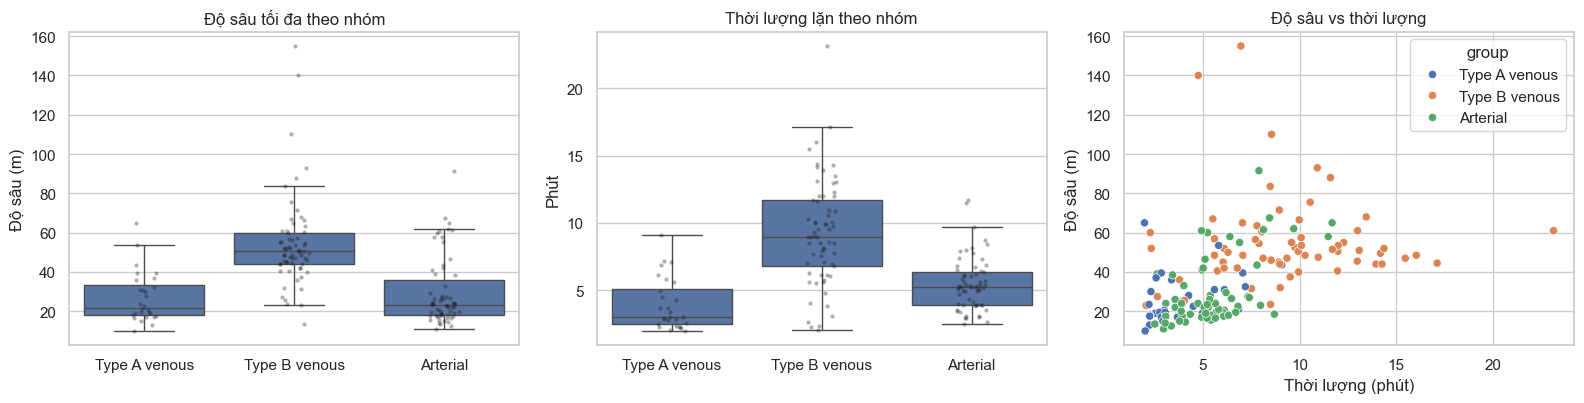

Spearman(thời lượng, độ sâu) = 0.609, p = 3.4e-17


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
order = ["Type A venous", "Type B venous", "Arterial"]

sns.boxplot(data=v, x="group", y="max_depth_clean", order=order, ax=ax[0], showfliers=False)
sns.stripplot(data=v, x="group", y="max_depth_clean", order=order, ax=ax[0], color="k", alpha=.35, size=3)
ax[0].set(title="Độ sâu tối đa theo nhóm", xlabel="", ylabel="Độ sâu (m)")

sns.boxplot(data=v, x="group", y="dur_min", order=order, ax=ax[1], showfliers=False)
sns.stripplot(data=v, x="group", y="dur_min", order=order, ax=ax[1], color="k", alpha=.35, size=3)
ax[1].set(title="Thời lượng lặn theo nhóm", xlabel="", ylabel="Phút")

sns.scatterplot(data=v, x="dur_min", y="max_depth_clean", hue="group", hue_order=order, ax=ax[2], s=35)
ax[2].set(title="Độ sâu vs thời lượng", xlabel="Thời lượng (phút)", ylabel="Độ sâu (m)")
plt.tight_layout(); save_show("dive_groups")

rho, p = stats.spearmanr(v.dur_min, v.max_depth_clean)
print(f"Spearman(thời lượng, độ sâu) = {rho:.3f}, p = {p:.2g}")

group,Arterial,Type A venous,Type B venous,tổng
bird,,,,
EP10,32,0,0,32
EP19,0,4,15,19
EP48,0,0,18,18
EP17,0,4,10,14
EP01,13,0,0,13
EP08,12,0,0,12
EP05,0,5,6,11
EP37,0,2,7,9
EP07,0,8,0,8


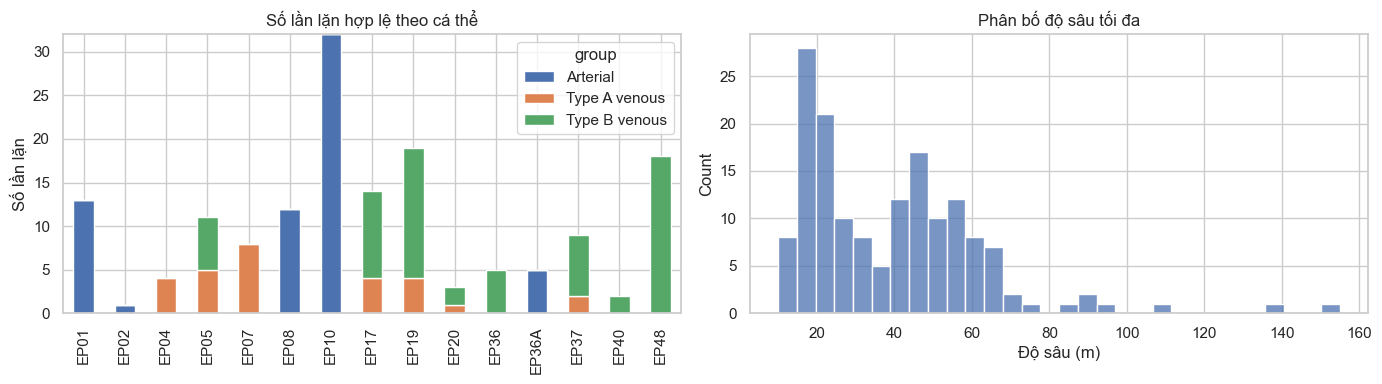

In [7]:
# Phân bố số lần lặn theo cá thể và nhóm
cnt = v.pivot_table(index="bird", columns="group", values="dive_id", aggfunc="count", fill_value=0)
cnt["tổng"] = cnt.sum(axis=1)
display(cnt.sort_values("tổng", ascending=False))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
cnt.drop(columns="tổng").plot(kind="bar", stacked=True, ax=ax[0])
ax[0].set(title="Số lần lặn hợp lệ theo cá thể", xlabel="", ylabel="Số lần lặn")
sns.histplot(v.max_depth_clean, bins=30, ax=ax[1])
ax[1].set(title="Phân bố độ sâu tối đa", xlabel="Độ sâu (m)")
plt.tight_layout(); save_show("dive_counts")

**Kiểm định giữa các nhóm.** Dữ liệu lệch phải và là đo lặp trên cùng một cá thể, nên dùng kiểm định phi tham số như một phép kiểm tra thô (chưa tính ảnh hưởng của từng cá thể).

In [8]:
groups = [g.max_depth_clean.values for _, g in v.groupby("group")]
H, p = stats.kruskal(*groups)
print(f"Kruskal-Wallis độ sâu giữa 3 nhóm: H = {H:.2f}, p = {p:.3g}")
groups = [g.dur_min.values for _, g in v.groupby("group")]
H, p = stats.kruskal(*groups)
print(f"Kruskal-Wallis thời lượng giữa 3 nhóm: H = {H:.2f}, p = {p:.3g}")

# So sánh từng cặp (Mann-Whitney, hiệu chỉnh Bonferroni cho 3 cặp)
from itertools import combinations
rows = []
for a, b in combinations(order, 2):
    x = v[v.group == a].max_depth_clean; y = v[v.group == b].max_depth_clean
    u, pp = stats.mannwhitneyu(x, y)
    rows.append((a, b, round(pp, 4), min(1, round(pp * 3, 4))))
pd.DataFrame(rows, columns=["nhóm A", "nhóm B", "p thô", "p Bonferroni"])

Kruskal-Wallis độ sâu giữa 3 nhóm: H = 56.92, p = 4.37e-13
Kruskal-Wallis thời lượng giữa 3 nhóm: H = 58.27, p = 2.22e-13


,nhóm A,nhóm B,p thô,p Bonferroni
0,Type A venous,Type B venous,0.0000,0.0
1,Type A venous,Arterial,0.7601,1.0
2,Type B venous,Arterial,0.0000,0.0


## 3. Chuỗi thời gian Hb/PO2: tổng quan
`Hb_pct` là độ bão hòa Hb (%) tính từ PO2 bằng đường cong Hill (P50 = 28,2 mmHg, n = 2,93), nên Hb và PO2 không độc lập: Hb là biến đổi đơn điệu của PO2.

In [9]:
inv = ts.groupby(["bird", "site"]).agg(
    mẫu=("t", "size"),
    lần_lặn=("dive_id", "nunique"),
    mẫu_trong_lặn=("dive_id", lambda s: s.notna().sum()),
    PO2_min=("PO2", "min"), PO2_med=("PO2", "median"), PO2_max=("PO2", "max"),
    Hb_min=("Hb_pct", "min"), Hb_med=("Hb_pct", "median"),
    sâu_max=("depth_m", "max"),
).round(1)
inv

,,mẫu,lần_lặn,mẫu_trong_lặn,PO2_min,PO2_med,PO2_max,Hb_min,Hb_med,sâu_max
bird,site,,,,,,,,,
EP01,arterial,2878,13,1156,28.0,88.0,218.0,49.5,96.5,91.0
EP02,arterial,17,1,13,35.0,100.0,128.0,65.3,97.6,25.5
EP04,venous,166,5,66,33.0,55.0,103.0,61.3,87.6,20.0
EP05,venous,2389,11,659,8.0,35.0,104.0,2.4,65.3,61.0
EP07,venous,3991,8,162,15.0,50.0,183.0,13.6,84.2,35.5
EP08,arterial,5173,12,720,29.0,65.0,149.0,52.0,92.0,27.5
EP10,arterial,4006,32,666,31.0,65.0,161.0,56.9,92.0,29.0
EP17,venous,3245,14,337,14.0,38.0,74.0,11.4,70.5,48.0
EP19,venous,2221,19,828,6.0,46.0,111.0,1.1,80.7,67.5


Tần suất khoảng cách mẫu (giây):


,số mẫu
dt,
15.0,19056
5.0,10437


Khoảng cách điển hình (trung vị): 15 s | >60 s (ngắt quãng): 0 mẫu


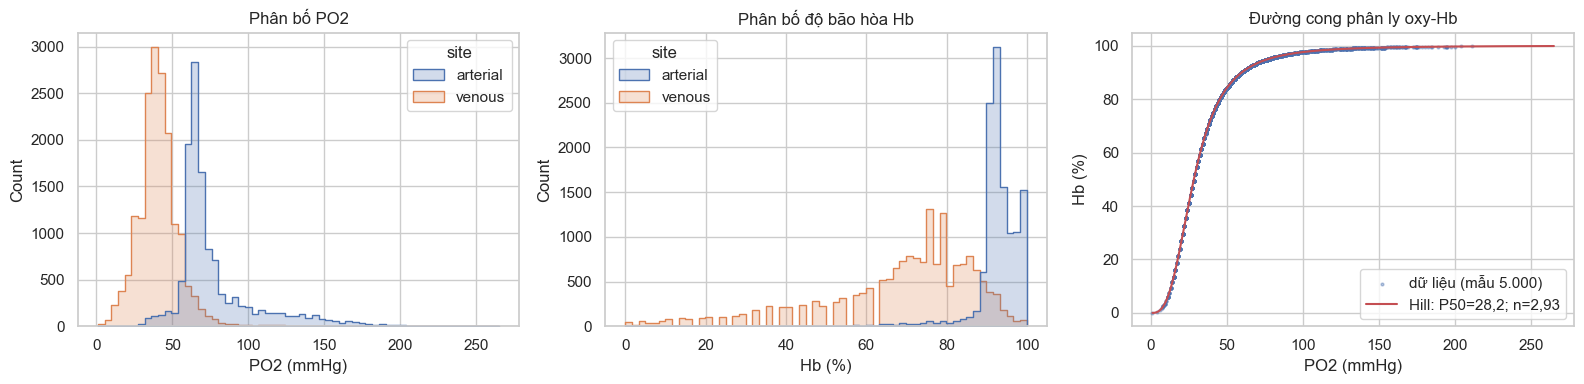

Sai lệch tuyệt đối lớn nhất so với Hill: 0.0518 điểm %


In [10]:
# Khoảng cách giữa hai mẫu liên tiếp (giây), tính trong từng chuỗi (bird, site)
s = ts.sort_values(["bird", "site", "t"]).copy()
s["dt"] = s.groupby(["bird", "site", "date"], dropna=False).t.diff()
print("Tần suất khoảng cách mẫu (giây):")
display(s.dt.value_counts().head(6).to_frame("số mẫu"))
print(f"Khoảng cách điển hình (trung vị): {s.dt.median():.0f} s | >60 s (ngắt quãng): {(s.dt > 60).sum()} mẫu")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(ts, x="PO2", hue="site", bins=60, ax=ax[0], element="step")
ax[0].set(title="Phân bố PO2", xlabel="PO2 (mmHg)")
sns.histplot(ts, x="Hb_pct", hue="site", bins=60, ax=ax[1], element="step")
ax[1].set(title="Phân bố độ bão hòa Hb", xlabel="Hb (%)")
po = np.linspace(1, 265, 300)
ax[2].scatter(ts.sample(5000, random_state=0).PO2, ts.sample(5000, random_state=0).Hb_pct, s=4, alpha=.4, label="dữ liệu (mẫu 5.000)")
ax[2].plot(po, 100 * po**2.93 / (28.2**2.93 + po**2.93), "r", label="Hill: P50=28,2; n=2,93")
ax[2].set(title="Đường cong phân ly oxy-Hb", xlabel="PO2 (mmHg)", ylabel="Hb (%)"); ax[2].legend()
plt.tight_layout(); save_show("hb_overview")

hill = 100 * ts.PO2**2.93 / (28.2**2.93 + ts.PO2**2.93)
print(f"Sai lệch tuyệt đối lớn nhất so với Hill: {(ts.Hb_pct - hill).abs().max():.4f} điểm %")

## 4. Hb theo pha và theo độ sâu

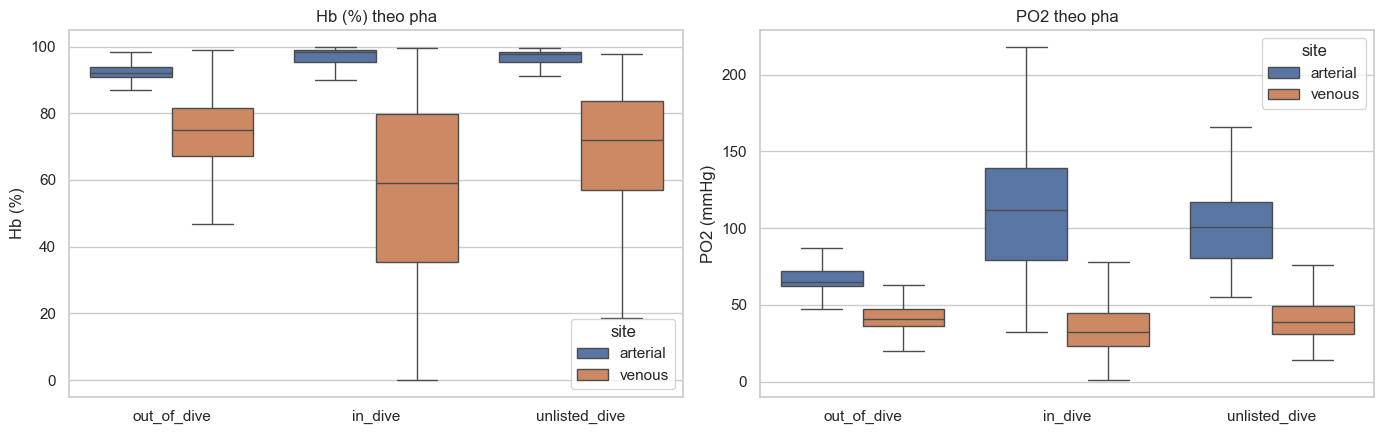

n  Hb_med  Hb_p10  PO2_med
site     phase                                        
arterial in_dive         2642    98.3    85.7    112.0
         out_of_dive     9315    92.0    89.7     65.0
         unlisted_dive    262    97.6    92.7    100.5
venous   excluded           2    92.6    91.3     67.5
         in_dive         3285    59.1    16.0     32.0
         out_of_dive    13293    74.9    52.5     41.0
         unlisted_dive    712    72.1    41.3     39.0

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ph_order = ["out_of_dive", "in_dive", "unlisted_dive"]
sns.boxplot(data=ts[ts.phase.isin(ph_order)], x="phase", y="Hb_pct", hue="site", order=ph_order, ax=ax[0], showfliers=False)
ax[0].set(title="Hb (%) theo pha", xlabel="", ylabel="Hb (%)")
sns.boxplot(data=ts[ts.phase.isin(ph_order)], x="phase", y="PO2", hue="site", order=ph_order, ax=ax[1], showfliers=False)
ax[1].set(title="PO2 theo pha", xlabel="", ylabel="PO2 (mmHg)")
plt.tight_layout(); save_show("hb_by_phase")

display(ts.groupby(["site", "phase"]).agg(n=("Hb_pct", "size"), Hb_med=("Hb_pct", "median"),
        Hb_p10=("Hb_pct", lambda s: s.quantile(.1)), PO2_med=("PO2", "median")).round(1))

n  Hb_med  Hb_q25  Hb_q75
site     depth_bin                              
arterial 0-1        5877    92.6    91.3    94.6
         1-5         539    96.7    89.7    98.1
         5-10        378    97.0    92.1    98.1
         10-20      1074    97.8    92.3    98.7
         20-30       293    97.8    93.2    98.8
         30-50       401    99.1    98.7    99.4
         50-80       296    99.3    99.2    99.5
         80+          23    99.5    99.3    99.7
venous   0-1        7826    70.5    61.3    78.6
         1-5        2560    70.5    63.3    76.2
         5-10        403    68.9    49.5    82.6
         10-20       874    70.5    38.4    85.0
         20-30       770    63.3    41.3    78.6
         30-50      1256    54.5    38.4    77.5
         50-80       255    38.4    32.6    63.3
         80+          42    61.3    39.6    68.9

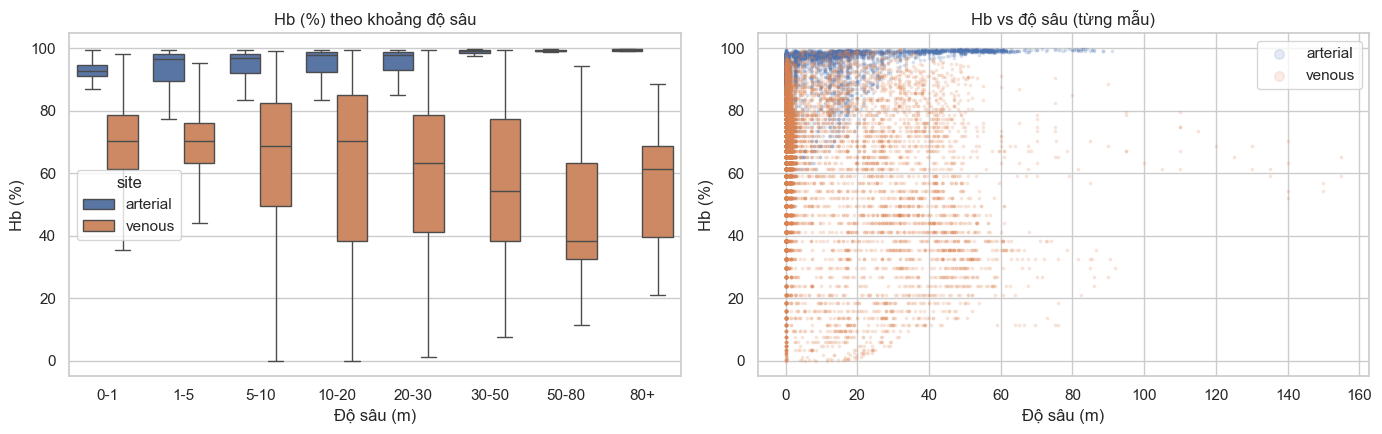

arterial : Spearman(độ sâu, Hb%) = +0.468  (n = 8,881, p = 0)
venous   : Spearman(độ sâu, Hb%) = -0.105  (n = 13,986, p = 2e-35)


In [12]:
# Hb theo khoảng độ sâu (chỉ dòng có độ sâu nội suy hợp lệ)
d = ts.dropna(subset=["depth_m"]).copy()
bins = [-0.01, 1, 5, 10, 20, 30, 50, 80, 200]
labels = ["0-1", "1-5", "5-10", "10-20", "20-30", "30-50", "50-80", "80+"]
d["depth_bin"] = pd.cut(d.depth_m, bins=bins, labels=labels)

tab = d.groupby(["site", "depth_bin"], observed=True).agg(n=("Hb_pct", "size"), Hb_med=("Hb_pct", "median"),
        Hb_q25=("Hb_pct", lambda s: s.quantile(.25)), Hb_q75=("Hb_pct", lambda s: s.quantile(.75))).round(1)
display(tab)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=d, x="depth_bin", y="Hb_pct", hue="site", ax=ax[0], showfliers=False)
ax[0].set(title="Hb (%) theo khoảng độ sâu", xlabel="Độ sâu (m)", ylabel="Hb (%)")
for site, g in d.groupby("site"):
    ax[1].scatter(g.depth_m, g.Hb_pct, s=3, alpha=.15, label=site)
ax[1].set(title="Hb vs độ sâu (từng mẫu)", xlabel="Độ sâu (m)", ylabel="Hb (%)"); ax[1].legend(markerscale=4)
plt.tight_layout(); save_show("hb_by_depth")

for site, g in d.groupby("site"):
    rho, p = stats.spearmanr(g.depth_m, g.Hb_pct)
    print(f"{site:9s}: Spearman(độ sâu, Hb%) = {rho:+.3f}  (n = {len(g):,}, p = {p:.2g})")

## 5. Diễn biến Hb trong một lần lặn
Chuẩn hóa thời gian về tỉ lệ 0-1 của mỗi lần lặn (0 = bắt đầu, 1 = kết thúc) để gộp được nhiều lần lặn có thời lượng khác nhau.

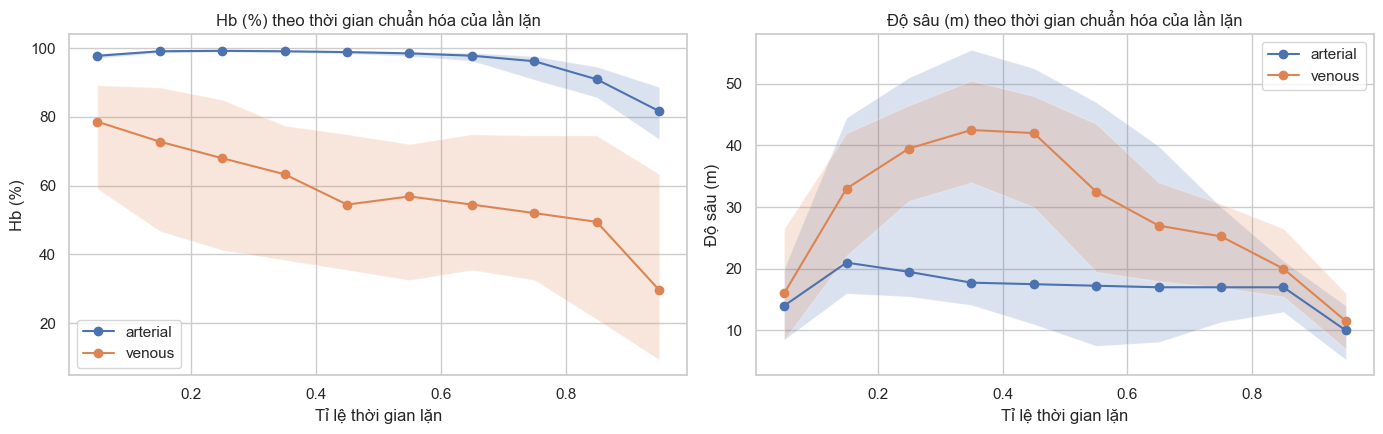

In [13]:
iv = ts[(ts.phase == "in_dive")].copy()
iv["frac"] = iv.t_in_dive_s / (iv.dive_dur_min * 60)
iv["frac_bin"] = pd.cut(iv.frac, np.linspace(0, 1, 11), include_lowest=True, labels=np.arange(5, 100, 10) / 100)
iv["frac_bin"] = iv.frac_bin.astype(float)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True)
for ycol, a, ttl in [("Hb_pct", ax[0], "Hb (%)"), ("depth_m", ax[1], "Độ sâu (m)")]:
    for site, g in iv.groupby("site"):
        m = g.groupby("frac_bin")[ycol].agg(["median", lambda s: s.quantile(.25), lambda s: s.quantile(.75)])
        m.columns = ["med", "q25", "q75"]
        a.plot(m.index, m.med, marker="o", label=site)
        a.fill_between(m.index, m.q25, m.q75, alpha=.2)
    a.set(title=f"{ttl} theo thời gian chuẩn hóa của lần lặn", xlabel="Tỉ lệ thời gian lặn", ylabel=ttl); a.legend()
plt.tight_layout(); save_show("dive_profile")

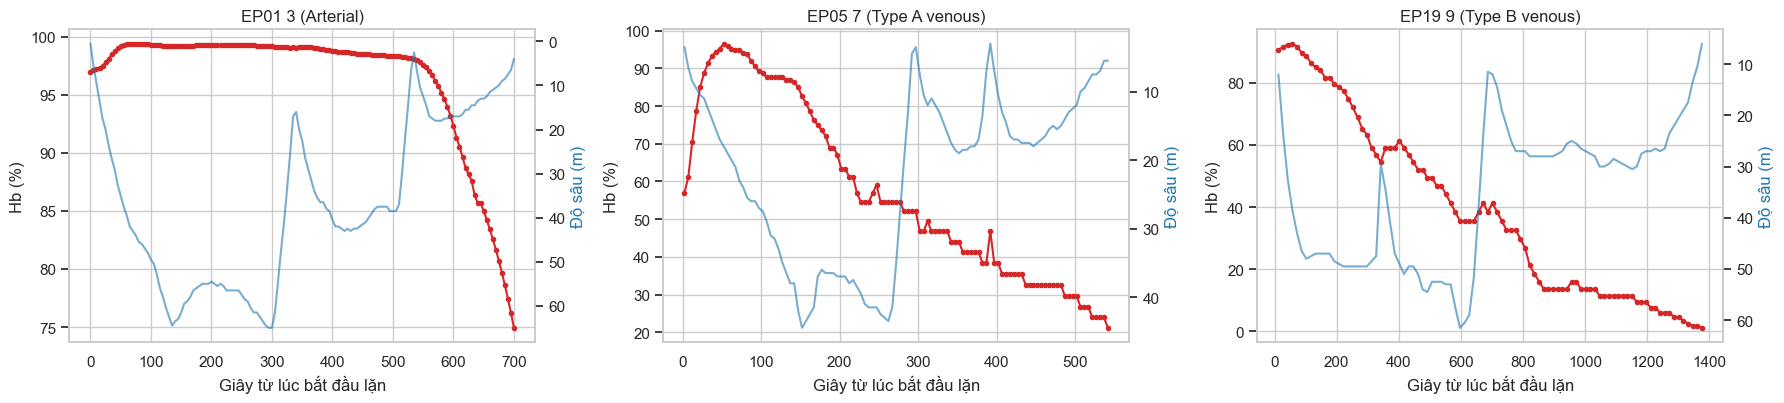

In [14]:
# Vẽ các lần lặn minh họa: lần lặn hợp lệ có nhiều mẫu nhất ở mỗi nhóm
n_per = iv.groupby("dive_id").size()
pick = (dives[dives.is_valid].assign(n=lambda x: x.dive_id.map(n_per))
        .sort_values("n", ascending=False).groupby("group").head(1))

fig, axes = plt.subplots(1, len(pick), figsize=(6 * len(pick), 4.2))
for ax1, (_, r) in zip(np.atleast_1d(axes), pick.iterrows()):
    g = iv[iv.dive_id == r.dive_id].sort_values("t_in_dive_s")
    ax1.plot(g.t_in_dive_s, g.Hb_pct, "o-", color="tab:red", ms=3)
    ax1.set(xlabel="Giây từ lúc bắt đầu lặn", ylabel="Hb (%)", title=f"{r.dive_id} ({r.group})")
    ax2 = ax1.twinx(); ax2.plot(g.t_in_dive_s, g.depth_m, color="tab:blue", alpha=.6)
    ax2.invert_yaxis(); ax2.set_ylabel("Độ sâu (m)", color="tab:blue"); ax2.grid(False)
plt.tight_layout(); save_show("example_dives")

## 6. Tóm tắt từng lần lặn và kiểm định thống kê
Nối chuỗi thời gian vào danh mục lần lặn để có một bảng 1 dòng / lần lặn. `Hb_base` là trung vị Hb ngoài lặn (pha `out_of_dive`) của cùng cá thể và vị trí lấy mẫu, dùng làm mức nền.

In [15]:
base = (ts[ts.phase == "out_of_dive"].groupby(["bird", "site"]).Hb_pct.median().rename("Hb_base").reset_index())

per = iv.groupby("dive_id").agg(
    n_mau=("Hb_pct", "size"), Hb_min=("Hb_pct", "min"), Hb_mean=("Hb_pct", "mean"),
    PO2_min=("PO2", "min"),
)
imin = iv.loc[iv.groupby("dive_id").Hb_pct.idxmin(), ["dive_id", "frac"]].set_index("dive_id").frac.rename("frac_at_min")
per = per.join(imin).reset_index()

P = (v.merge(per, on="dive_id", how="inner")
       .merge(base, on=["bird", "site"], how="left"))
P["Hb_drop"] = P.Hb_base - P.Hb_min
print("Số lần lặn có dữ liệu Hb:", len(P))
display(P[["dive_id","group","max_depth_clean","dur_min","n_mau","Hb_base","Hb_min","Hb_drop","PO2_min","frac_at_min"]].round(2).head(10))
display(P.groupby("group")[["Hb_base","Hb_min","Hb_drop","PO2_min"]].agg(["mean","median"]).round(1))

Số lần lặn có dữ liệu Hb: 156


,dive_id,group,max_depth_clean,dur_min,n_mau,Hb_base,Hb_min,Hb_drop,PO2_min,frac_at_min
0,EP04 1,Type A venous,16.5,3.72,15,84.23,65.29,18.94,35.0,0.11
1,EP05 1,Type B venous,13.5,3.12,38,67.13,59.14,8.00,32.0,0.99
2,EP02 2,Arterial,24.0,3.08,13,85.91,80.71,5.20,46.0,0.97
3,EP04 2,Type A venous,20.5,3.02,12,84.23,81.67,2.56,47.0,0.04
4,EP05 5,Type B venous,56.9,5.60,67,67.13,9.40,57.74,13.0,0.10
5,EP36A 1,Arterial,25.0,3.93,15,92.33,90.53,1.80,61.0,0.88
6,EP04 3,Type A venous,19.0,2.53,10,84.23,73.55,10.68,40.0,0.19
7,EP05 6,Type B venous,52.0,6.10,73,67.13,13.62,53.51,15.0,0.97
8,EP36A 3,Arterial,41.0,4.97,19,92.33,96.19,-3.86,85.0,0.05
9,EP04 4,Type A venous,21.0,6.85,27,84.23,78.61,5.62,44.0,0.98


Hb_base        Hb_min        Hb_drop        PO2_min       
                 mean median   mean median    mean median    mean median
group                                                                   
Arterial         92.5   92.0   78.5   77.5    13.9   15.8    48.3   43.0
Type A venous    78.1   81.7   70.0   74.9     8.0    3.9    44.9   41.0
Type B venous    71.6   70.5   29.0   23.9    42.6   46.2    20.0   19.0

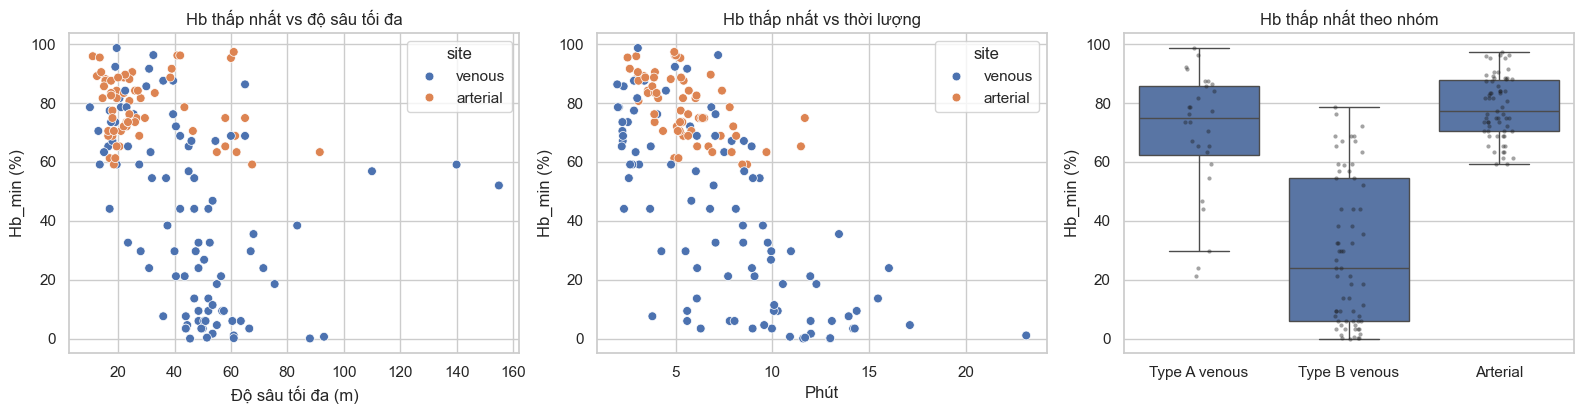

arterial  | Spearman(Hb_min, max_depth_clean) = -0.148  (n = 63, p = 0.25)
arterial  | Spearman(Hb_min, dur_min        ) = -0.606  (n = 63, p = 1.4e-07)
venous    | Spearman(Hb_min, max_depth_clean) = -0.557  (n = 93, p = 6.9e-09)
venous    | Spearman(Hb_min, dur_min        ) = -0.726  (n = 93, p = 1.8e-16)


In [16]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
sns.scatterplot(data=P, x="max_depth_clean", y="Hb_min", hue="site", ax=ax[0], s=40)
ax[0].set(title="Hb thấp nhất vs độ sâu tối đa", xlabel="Độ sâu tối đa (m)", ylabel="Hb_min (%)")
sns.scatterplot(data=P, x="dur_min", y="Hb_min", hue="site", ax=ax[1], s=40)
ax[1].set(title="Hb thấp nhất vs thời lượng", xlabel="Phút", ylabel="Hb_min (%)")
sns.boxplot(data=P, x="group", y="Hb_min", order=["Type A venous", "Type B venous", "Arterial"], ax=ax[2], showfliers=False)
sns.stripplot(data=P, x="group", y="Hb_min", order=["Type A venous", "Type B venous", "Arterial"], ax=ax[2], color="k", alpha=.4, size=3)
ax[2].set(title="Hb thấp nhất theo nhóm", xlabel="", ylabel="Hb_min (%)")
plt.tight_layout(); save_show("per_dive_scatter")

for site, g in P.groupby("site"):
    for col in ["max_depth_clean", "dur_min"]:
        rho, p = stats.spearmanr(g[col], g.Hb_min)
        print(f"{site:9s} | Spearman(Hb_min, {col:15s}) = {rho:+.3f}  (n = {len(g)}, p = {p:.2g})")

In [17]:
# Động mạch vs tĩnh mạch
a = P[P.site == "arterial"].Hb_min; b = P[P.site == "venous"].Hb_min
u, p = stats.mannwhitneyu(a, b)
print(f"Hb_min động mạch (trung vị {a.median():.1f}%) vs tĩnh mạch ({b.median():.1f}%): Mann-Whitney p = {p:.3g}")

# Kiểm tra độ nhạy: lấy trung bình theo cá thể để tránh coi các lần lặn cùng một con là độc lập
bm = P.groupby(["bird", "site"]).Hb_min.mean().reset_index()
display(bm.pivot(index="bird", columns="site", values="Hb_min").round(1))
a2 = bm[bm.site == "arterial"].Hb_min; b2 = bm[bm.site == "venous"].Hb_min
print(f"Mức cá thể: n_arterial = {len(a2)}, n_venous = {len(b2)}, Mann-Whitney p = {stats.mannwhitneyu(a2, b2).pvalue:.3g}")

Hb_min động mạch (trung vị 77.5%) vs tĩnh mạch (38.4%): Mann-Whitney p = 8.87e-14


site,arterial,venous
bird,,
EP01,73.2,NaN
EP02,80.7,NaN
EP04,NaN,74.8
EP05,NaN,29.4
EP07,NaN,75.1
EP08,77.9,NaN
EP10,78.5,NaN
EP17,NaN,59.0
EP19,NaN,38.8


Mức cá thể: n_arterial = 5, n_venous = 10, Mann-Whitney p = 0.00266



## 7. Kết luận và lưu ý

**Chất lượng dữ liệu**
- Hai file nhất quán với nhau: không trùng bản ghi `(bird, site, t)`, PO2 và Hb nằm trong khoảng vật lý hợp lệ, `Hb_pct` khớp đường cong Hill (sai lệch tối đa ~0,05 điểm %).
- 156/160 lần lặn dùng được; 4 lần bị loại do thiếu mẫu Hb (EP04 5, EP36A 8, EP07 9, EP07 10).
- EP36A và EP37 không có ngày (chỉ có giờ trong ngày), nên không vẽ được trục thời gian tuyệt đối cho hai cá thể này.

**Phát hiện chính**
1. **Ba nhóm lặn không giống nhau.** Type B venous lặn sâu và lâu hơn rõ rệt (trung vị ~50 m, ~9 phút) so với Type A venous (~22 m, ~3 phút) và Arterial (~23 m, ~5 phút). Hai nhóm sau không khác nhau về độ sâu. Độ sâu và thời lượng tương quan dương khá mạnh (Spearman ≈ 0,61).
2. **Máu tĩnh mạch và động mạch phản ứng ngược nhau.** Ở động mạch, Hb trong lúc lặn cao hơn ngoài lặn (trung vị ~98% so với ~92%) và tăng theo độ sâu; ở tĩnh mạch, Hb giảm khi lặn (trung vị ~59% so với ~75%) và giảm theo độ sâu và thời lượng.
3. **Mức tụt Hb tĩnh mạch rất lớn ở lần lặn dài.** Hb_min tĩnh mạch có tương quan âm mạnh với thời lượng (ρ ≈ -0,73) và độ sâu (ρ ≈ -0,56); nhóm Type B có Hb_min trung vị ~24%.
4. **Ở động mạch, thời lượng là yếu tố liên quan rõ hơn độ sâu** (ρ ≈ -0,61 với thời lượng; không có ý nghĩa với độ sâu).

**Hạn chế cần nhớ khi diễn giải**
- Nhóm và cá thể bị trộn lẫn: mỗi chim chủ yếu thuộc một nhóm (xem bảng ở mục 2), nên khác biệt giữa nhóm có thể một phần là khác biệt giữa các cá thể. Chỉ có 5 chim động mạch và 10 chim tĩnh mạch; kiểm định mức cá thể ở mục 6 là phép kiểm tra thận trọng hơn.
- Các kiểm định ở mục 2 và 6 coi các lần lặn là độc lập, trong khi nhiều lần lặn đến từ cùng một con. Muốn kết luận chặt chẽ nên dùng mô hình hỗn hợp (hiệu ứng ngẫu nhiên theo cá thể).
- `Hb_pct` được tính từ PO2 bằng một đường cong Hill cố định, nên "Hb" ở đây là độ bão hòa suy ra, không phải đo độc lập.
- `Hb_base` lấy từ pha ngoài lặn của chính cá thể đó, có thể nhiễu nếu phần nền ngắn (ví dụ EP02 chỉ có 17 mẫu).

**Hướng mở rộng:** mô hình hỗn hợp `Hb_min ~ độ sâu + thời lượng + vị trí lấy mẫu + (1 | cá thể)`; phân tích tốc độ giảm bão hòa (dHb/dt) trong từng lần lặn; xử lý riêng các đợt lặn ngoài bảng (`unlisted_dive`).
